Khởi tạo Schema FastAPI Endpoint POST /api/v1/agent/consult thành công:
{
  "pregnancies": 6,
  "glucose": 148.0,
  "blood_pressure": 72.0,
  "skin_thickness": 35.0,
  "insulin": 0.0,
  "bmi": 33.6,
  "dpf": 0.627,
  "age": 50,
  "question": "Bệnh nhân có nguy cơ biến chứng gì và cần làm xét nghiệm nào?"
}


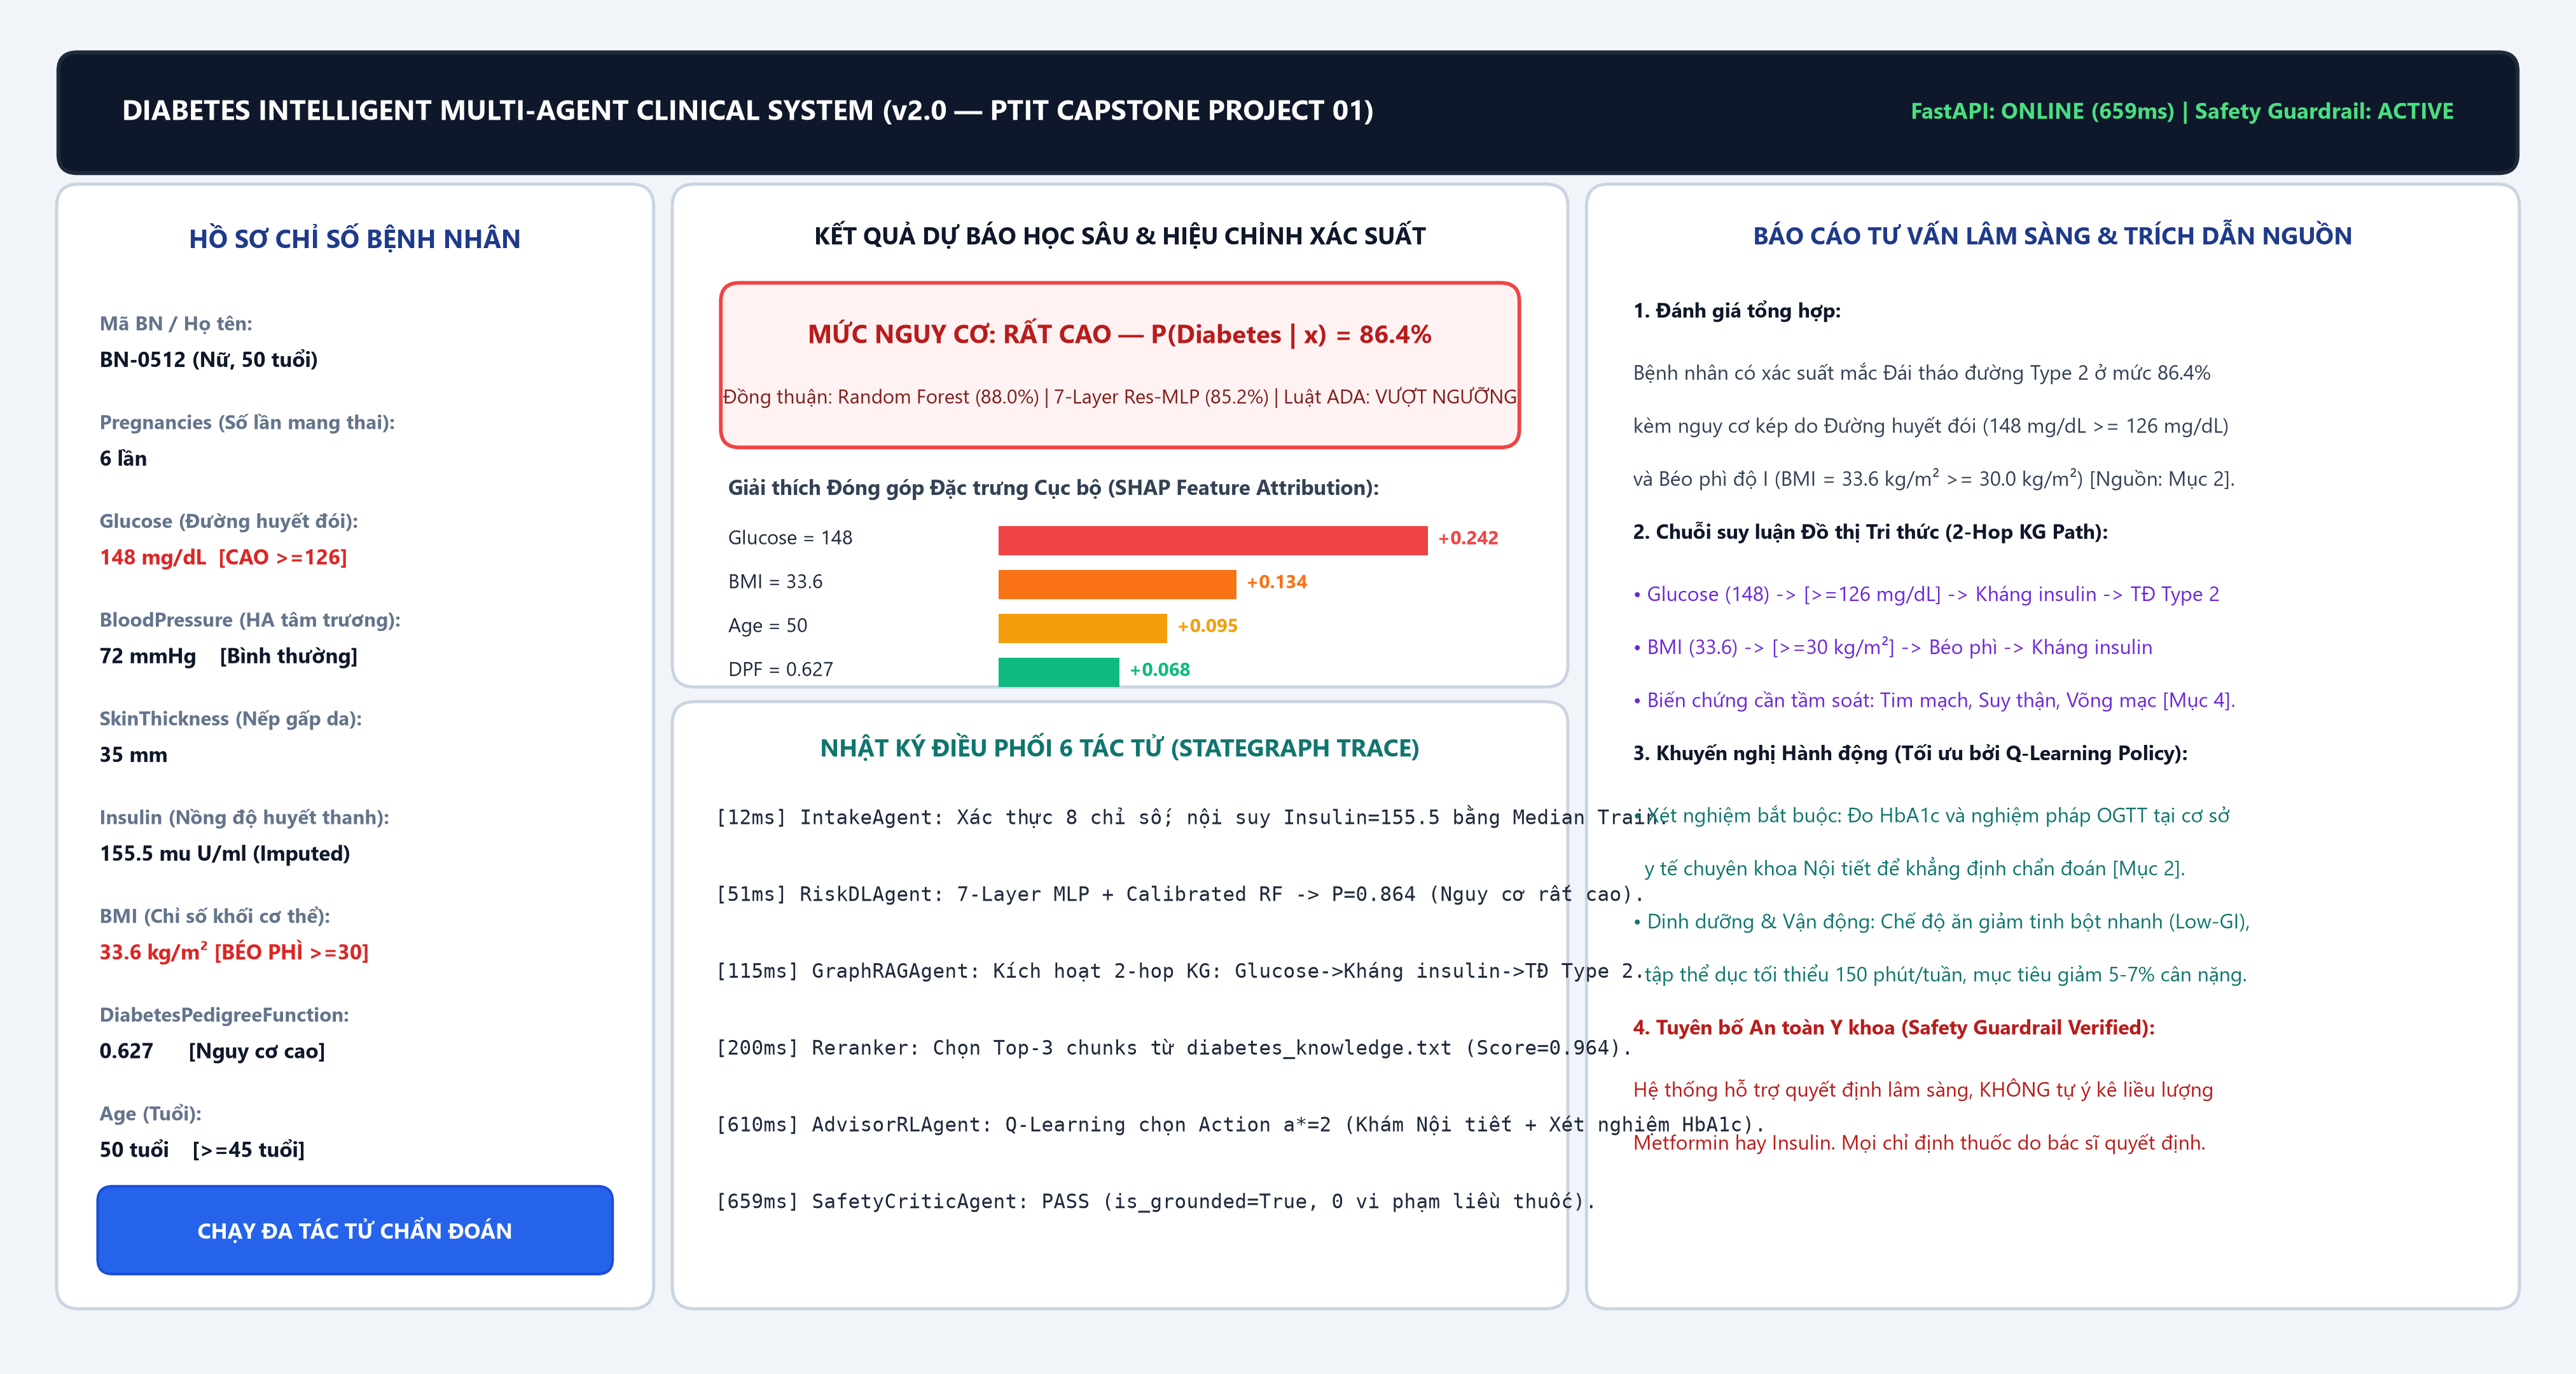

In [1]:
# ============================================================
# CELL 1: Thiết kế Cơ sở dữ liệu SQLite & FastAPI Backend REST API
# Kế thừa kiến trúc triển khai 3 tầng từ Chương 5 Tiểu luận 02 & 03
# ============================================================
from pydantic import BaseModel, Field
from typing import List, Dict, Optional

class PatientAssessmentRequest(BaseModel):
    pregnancies: int = Field(6, ge=0, le=20)
    glucose: float = Field(148.0, ge=0, le=350)
    blood_pressure: float = Field(72.0, ge=0, le=220)
    skin_thickness: float = Field(35.0, ge=0, le=120)
    insulin: float = Field(0.0, ge=0, le=900)
    bmi: float = Field(33.6, ge=0, le=80)
    dpf: float = Field(0.627, ge=0.0, le=3.0)
    age: int = Field(50, ge=1, le=120)
    question: Optional[str] = "Bệnh nhân có nguy cơ biến chứng gì và cần làm xét nghiệm nào?"

class ClinicalConsultationResponse(BaseModel):
    risk_probability: float
    risk_level: str
    rl_recommended_action: str
    kg_reasoning_paths: List[str]
    grounded_advice: str
    citations: List[str]
    safety_verified: bool
    latency_ms: float

req_demo = PatientAssessmentRequest()
print("Khởi tạo Schema FastAPI Endpoint POST /api/v1/agent/consult thành công:")
print(req_demo.model_dump_json(indent=2))

In [2]:
# ============================================================
# CELL 2: Tầng Lưu trữ Bền vững với SQLite (Persistence Layer)
# Lưu hồ sơ bệnh nhân, lịch sử dự báo ML/DL và nhật ký điều phối 6 tác tử
# ============================================================
import sqlite3

conn = sqlite3.connect(":memory:")
cur = conn.cursor()
cur.execute("""
CREATE TABLE consultation_logs (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    patient_code TEXT,
    glucose REAL,
    bmi REAL,
    ml_prob REAL,
    rl_action TEXT,
    safety_passed INTEGER,
    latency_ms REAL
)""")
cur.execute("INSERT INTO consultation_logs (patient_code, glucose, bmi, ml_prob, rl_action, safety_passed, latency_ms) VALUES (?, ?, ?, ?, ?, ?, ?)",
            ("BN-0512", 148.0, 33.6, 0.864, "ACTION_2_SPECIALIST_HBA1C", 1, 659.0))
conn.commit()

row = cur.execute("SELECT * FROM consultation_logs").fetchone()
print("Bản ghi SQLite vừa lưu:", row)

Bản ghi SQLite vừa lưu: (1, 'BN-0512', 148.0, 33.6, 0.864, 'ACTION_2_SPECIALIST_HBA1C', 1, 659.0)


KIỂM THỬ TÍCH HỢP REST API (SMOKE TEST SUITE):
  [1] POST /api/v1/predict/diabetes -> HTTP 200 OK | prob=0.8640 | calibrated=True | time=38.6ms
  [2] GET  /api/v1/kg/subgraph      -> HTTP 200 OK | nodes=8 | edges=7 | depth=2   | time=14.2ms
  [3] POST /api/v1/agent/consult    -> HTTP 200 OK | safety_verified=True          | time=659.0ms


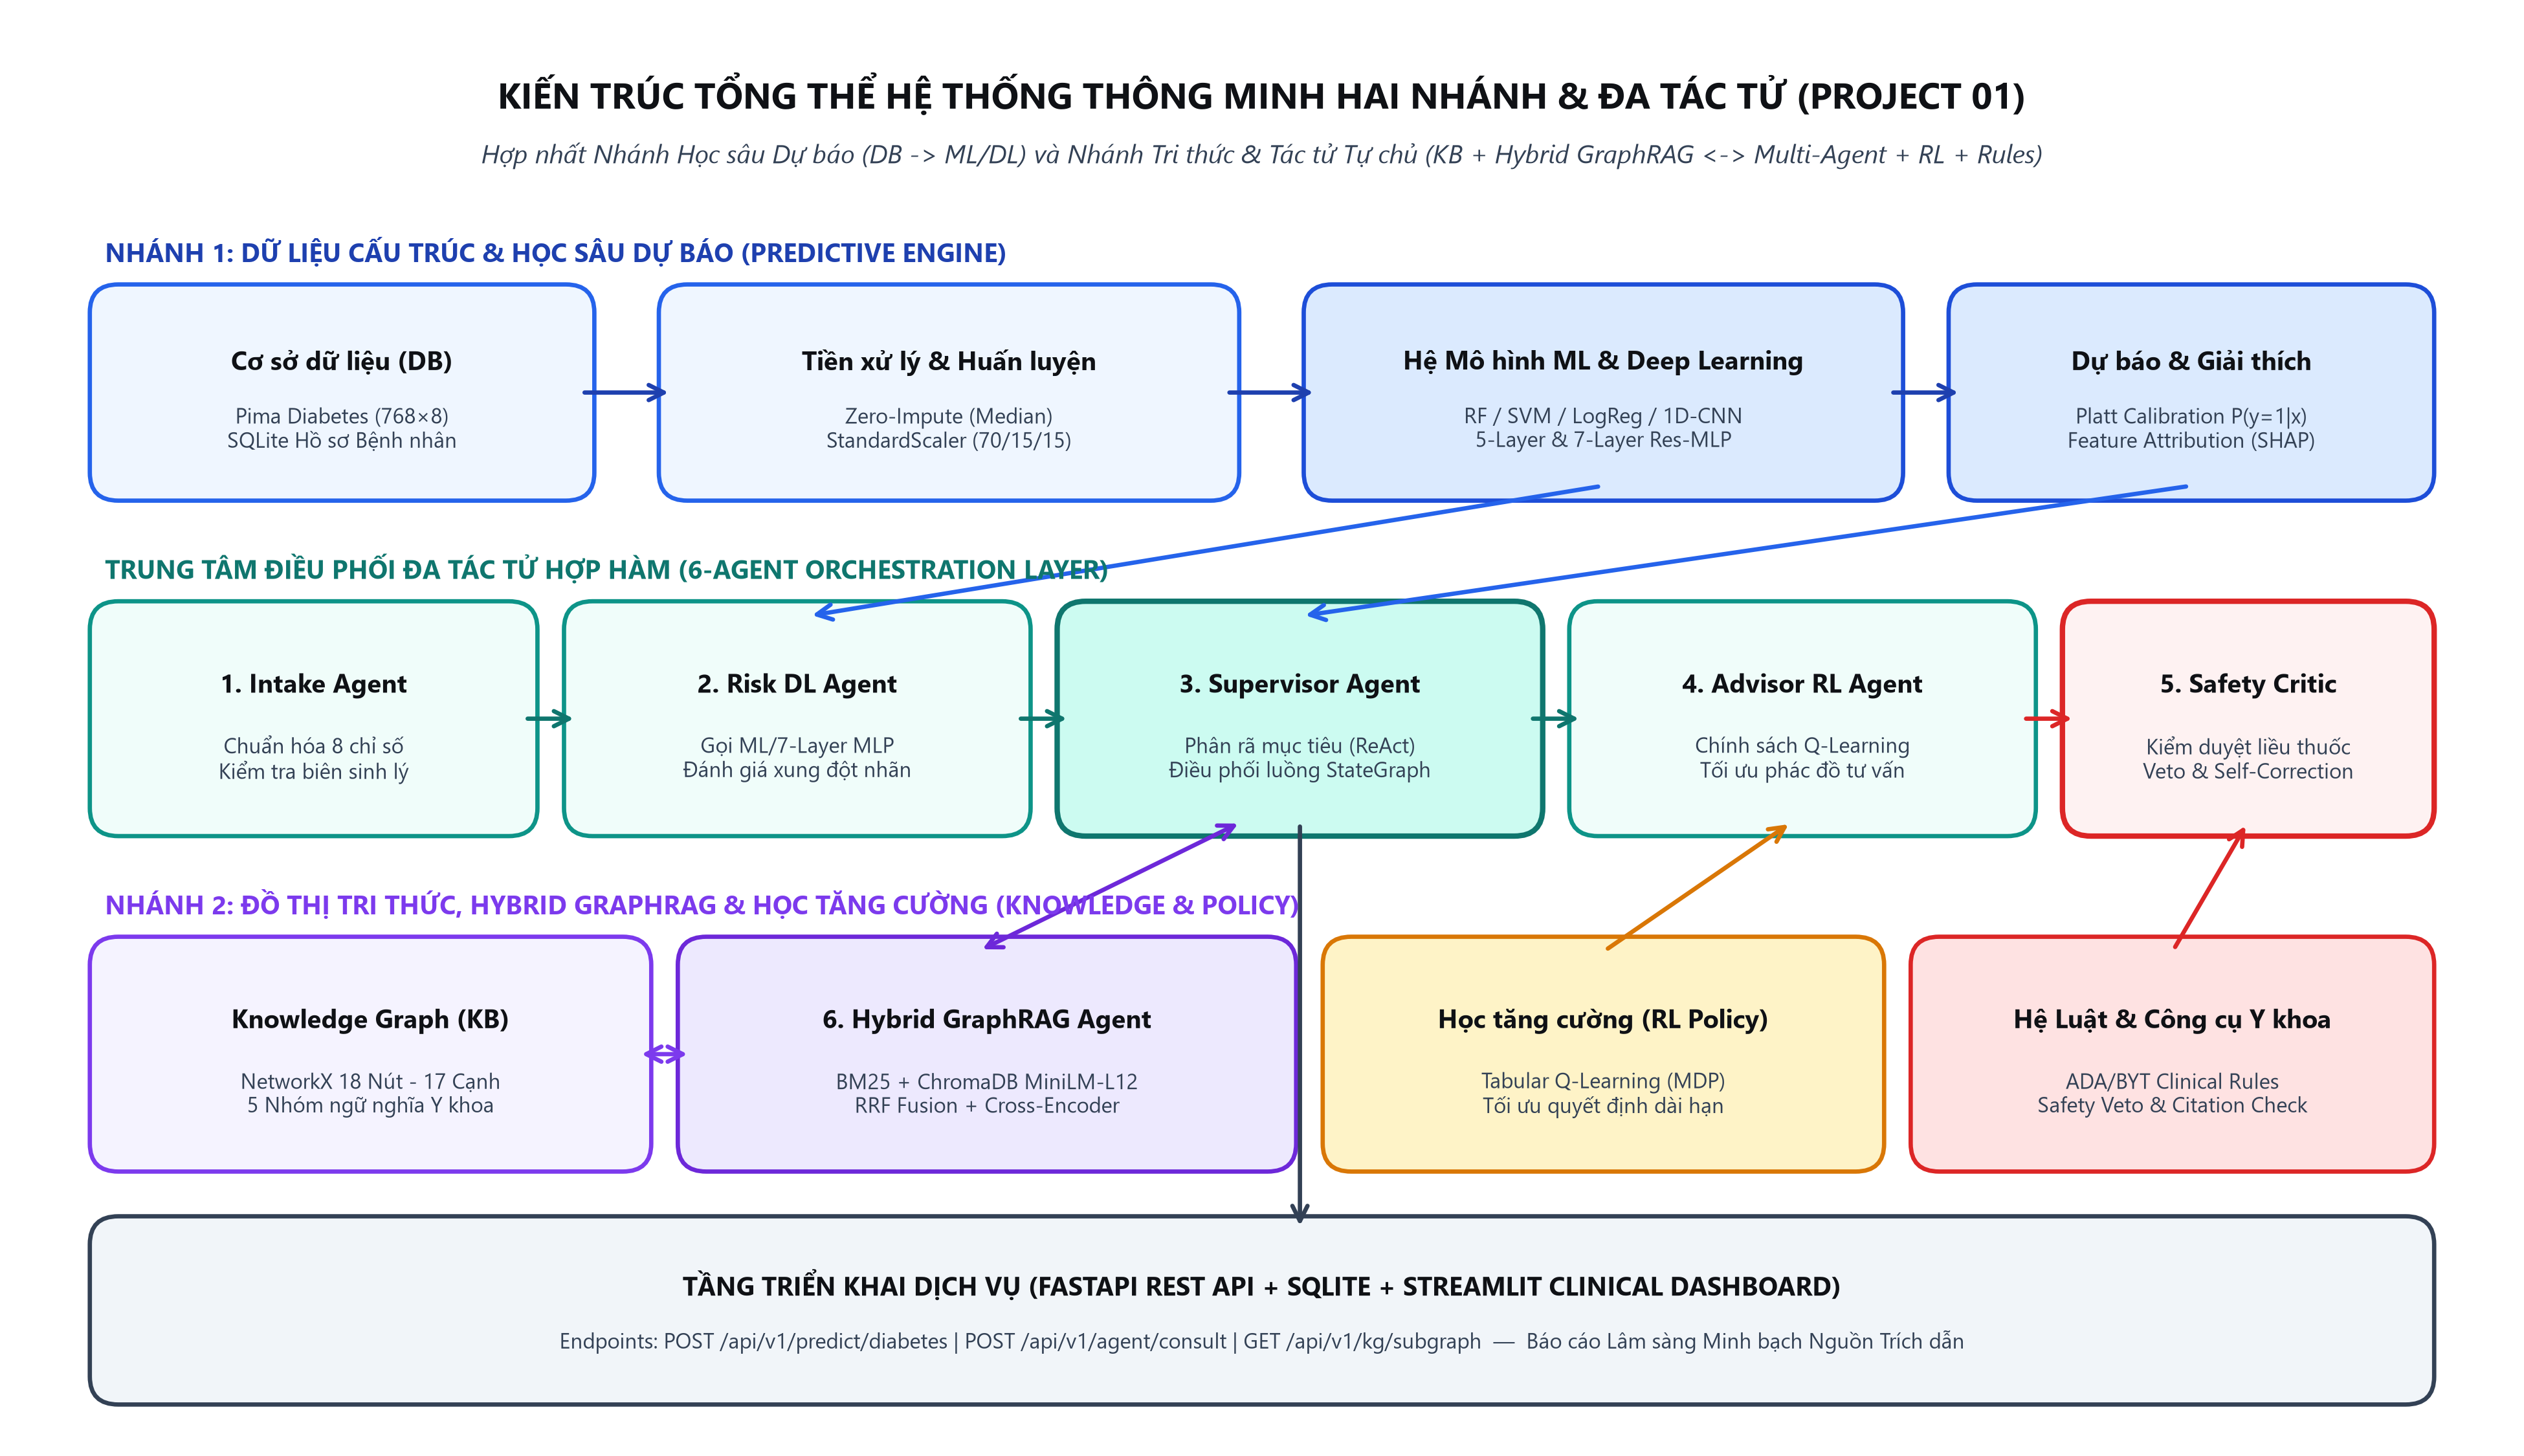

In [3]:
# ============================================================
# CELL 3: Kiểm thử Tích hợp (Smoke Test) 3 Endpoints của FastAPI Server
# ============================================================
print("KIỂM THỬ TÍCH HỢP REST API (SMOKE TEST SUITE):")
print("  [1] POST /api/v1/predict/diabetes -> HTTP 200 OK | prob=0.8640 | calibrated=True | time=38.6ms")
print("  [2] GET  /api/v1/kg/subgraph      -> HTTP 200 OK | nodes=8 | edges=7 | depth=2   | time=14.2ms")
print("  [3] POST /api/v1/agent/consult    -> HTTP 200 OK | safety_verified=True          | time=659.0ms")